# Introduction à la Visualisation des Données

# Cours de Visualisation des données - Master 1 DSIM - Université de Dschang
Auteurs: 
  - NKFUTU Oscar
  - PALI Essonani Ma-Joie 
  - KABUYA Arsène


In [3]:
# Importation des modules nécessaires

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import squarify
import plotly.express as px
import plotly.io as pio
import plotly.graph_objects as go
import networkx as nx

# Types de graphiques
## 1. Comparer des catégories
### 1.1. Diagramme en Barres vertical (Bar Chart)

- **Variables impliquées** : une variable *qualitative (nominale ou ordinale)* sur l'axe X, et une variable *quantitative (continue ou discrète)* sur l'axe Y.

- **Cas d'utilisation** : comparer la valeur absolue d'une métrique entre différentes catégories.

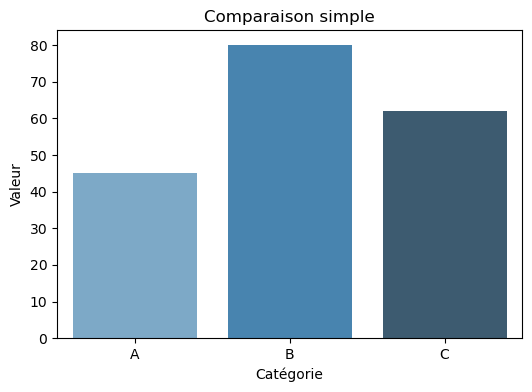

In [4]:
# Code Python

df = pd.DataFrame({'Catégorie': ['A', 'B', 'C'], 'Valeur': [45, 80, 62]})
plt.figure(figsize=(6, 4))
sns.barplot(x='Catégorie', y='Valeur', data=df, palette='Blues_d', hue='Catégorie', legend=False)
plt.title("Comparaison simple")
plt.show()

### 1.2. Diagramme en Barres horizontal (Horizontal Bar Chart)

- **Variables impliquées** : une variable *qualitative (nominale/ordinale)* sur l'axe Y, et une variable *quantitative (continue/discrète)* sur l'axe X.

- **Cas d'utilisation** : identique au diagramme vertical, mais indispensable lorsque les noms des catégories sont longs ou qu'il y a plus de 7-8 catégories.

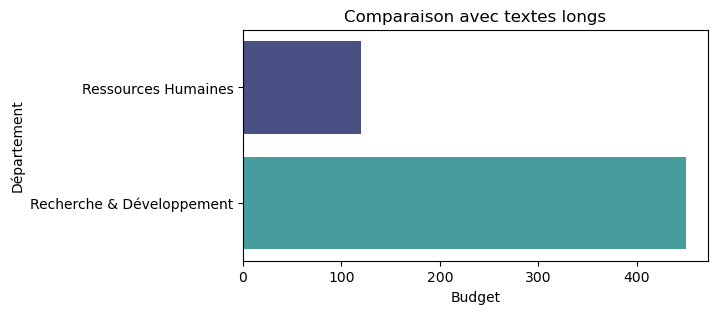

In [5]:
# Code Python

df = pd.DataFrame({'Département': ['Ressources Humaines', 'Recherche & Développement'], 'Budget': [120, 450]})
plt.figure(figsize=(6, 3))
sns.barplot(x='Budget', y='Département', data=df, palette='mako', hue='Département', legend=False)
plt.title("Comparaison avec textes longs")
plt.show()

## 2. Montrer une distribution
### 2.1. Histogramme (Histogram)

- **Variables impliquées** : une variable *quantitative (continue ou discrète)*.

- **Cas d'utilisation** : voir comment se répartissent les valeurs d'une seule variable en regroupant les données dans des intervalles (bins).

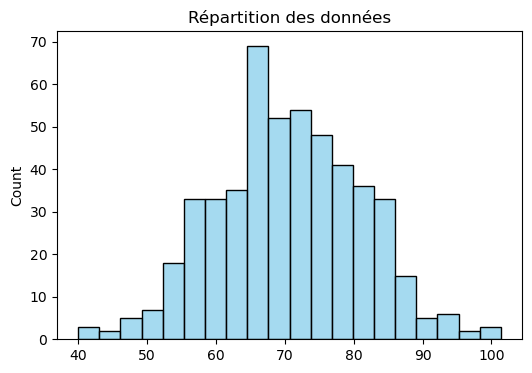

In [6]:
# Code Python

data = np.random.normal(70, 10, 500)
plt.figure(figsize=(6, 4))
sns.histplot(data, bins=20, color='skyblue')
plt.title("Répartition des données")
plt.show()

### 2.2. Courbe de Densité (KDE Plot)

- **Variables impliquées** : une variable *quantitative (continue)*.

- **Cas d'utilisation** : version lissée de l'histogramme, idéale pour visualiser la forme globale d'une distribution sans le biais visuel des intervalles.

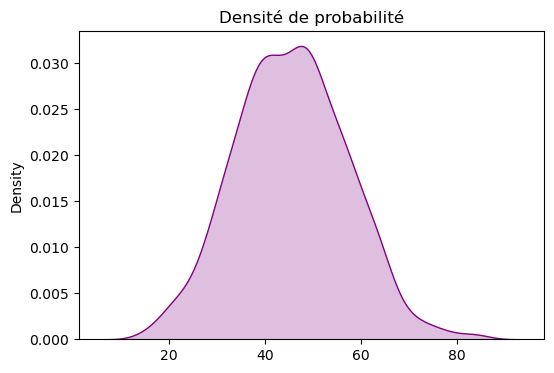

In [7]:
# Code Python

data = np.random.normal(45, 12, 1000)
plt.figure(figsize=(6, 4))
sns.kdeplot(data, fill=True, color='purple')
plt.title("Densité de probabilité")
plt.show()

### 2.3. Boîte à Moustaches (Boxplot)

- **Variables impliquées** : une variable *qualitative (nominale)*, et une variable *quantitative (continue ou discrète)*.

- **Cas d'utilisation** : comparer les médianes, quartiles et identifier les valeurs aberrantes (outliers) entre plusieurs groupes.

    

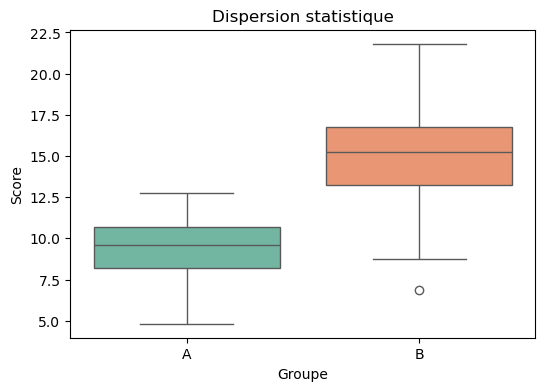

In [8]:
# Code Python

df = pd.DataFrame({'Groupe': ['A']*50 + ['B']*50, 'Score': np.concatenate([np.random.normal(10, 2, 50), np.random.normal(15, 3, 50)])})
plt.figure(figsize=(6, 4))
sns.boxplot(x='Groupe', y='Score', data=df, palette='Set2', hue='Groupe', legend=False)
plt.title("Dispersion statistique")
plt.show()

### 2.4. Graphique en Violon (Violin Plot)

- **Variables impliquées** : une variable *qualitative (nominale)*, et une variable *quantitative (continue)*.

- **Cas d'utilisation** : combine le boxplot et le KDE plot. Montre la statistique (quartiles) et la densité de la distribution.

    

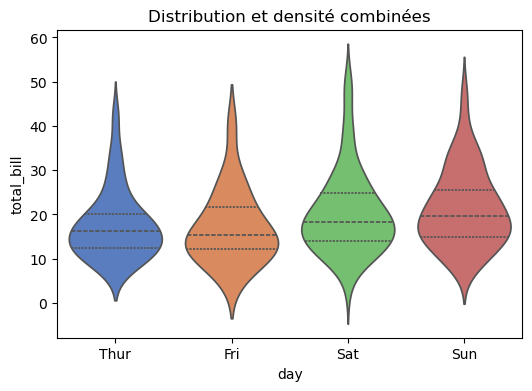

In [9]:
# Code Python

tips = sns.load_dataset('tips')
plt.figure(figsize=(6, 4))
sns.violinplot(x='day', y='total_bill', data=tips, palette='muted', inner='quartile', hue='day', legend=False)
plt.title("Distribution et densité combinées")
plt.show()

## 3. Analyser des relations
### 3.1. Nuage de points (Scatter Plot)

- **Variables impliquées** : 2 variables *quantitatives (continues ou discrètes)* pour les axes X et Y.

- **Cas d'utilisation** : identifier une corrélation, une tendance ou des clusters entre deux variables numériques.

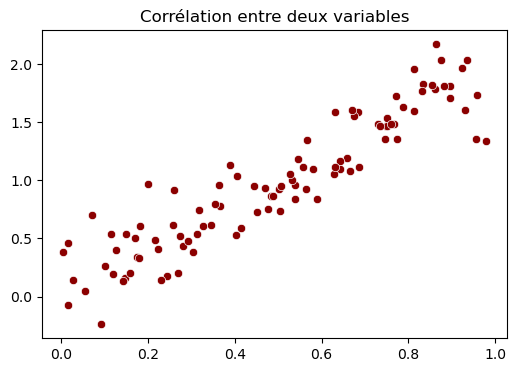

In [10]:
# Code Python

x = np.random.rand(100)
y = x * 2 + np.random.normal(0, 0.2, 100)
plt.figure(figsize=(6, 4))
sns.scatterplot(x=x, y=y, color='darkred')
plt.title("Corrélation entre deux variables")
plt.show()

### 3.2. Graphique à bulles (Bubble Chart)

- **Variables impliquées** : 3 variables *quantitatives* (axes X, Y, et Taille de bulle), et éventuellement une variable *qualitative nominale (couleur)*.

- **Cas d'utilisation** : évaluer la relation entre 3 ou 4 variables simultanément.


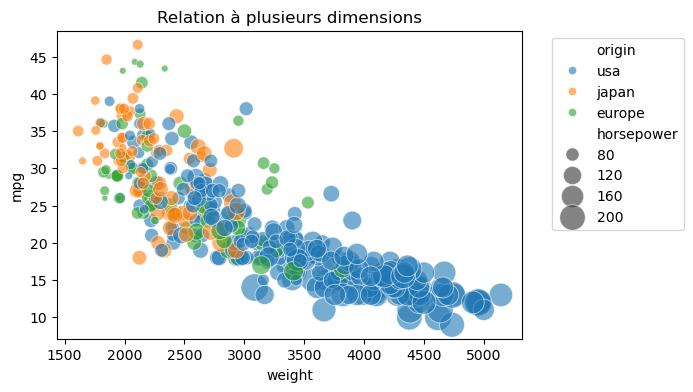

In [11]:
# Code Python

mpg = sns.load_dataset('mpg').dropna()
plt.figure(figsize=(6, 4))
sns.scatterplot(data=mpg, x='weight', y='mpg', size='horsepower', hue='origin', sizes=(20, 400), alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("Relation à plusieurs dimensions")
plt.show()

### 3.3. Carte de chaleur (Heatmap)

- **Variables impliquées** : 2 variables *qualitatives* (pour construire la grille des axes X/Y), et une variable *quantitative* (pour l'intensité de la couleur).

- **Cas d'utilisation** : visualiser des matrices de corrélation ou croiser deux variables catégorielles pour y lire une troisième variable sous forme d'intensité lumineuse.

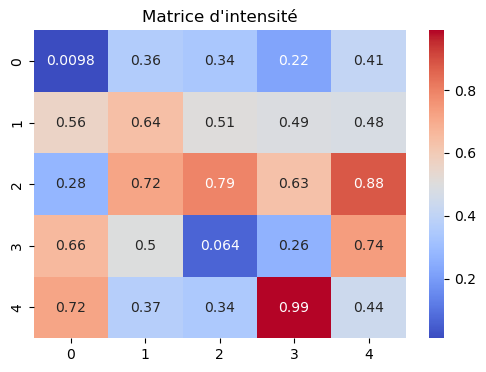

In [12]:
# Code Python

matrice = np.random.rand(5, 5)
plt.figure(figsize=(6, 4))
sns.heatmap(matrice, annot=True, cmap='coolwarm')
plt.title("Matrice d'intensité")
plt.show()

## 4. Observer une évolution (Séries temporelles)
### 4.1. Graphique en courbes (Line Chart)

- **Variables impliquées** : une variable *quantitative continue ou discrète ordonnée* (généralement le Temps sur l'axe X), et une variable *quantitative continue* (sur l'axe Y).

- **Cas d'utilisation** : suivre l'évolution et les tendances d'une ou plusieurs métriques de manière continue.


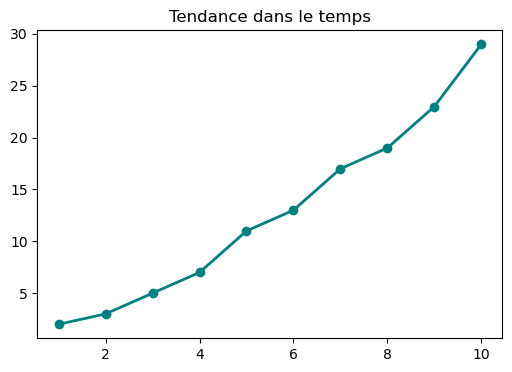

In [13]:
# Code Python

temps = np.arange(1, 11)
valeur = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29]
plt.figure(figsize=(6, 4))
plt.plot(temps, valeur, marker='o', color='teal', linewidth=2)
plt.title("Tendance dans le temps")
plt.show()

### 4.2. Graphique en aires empilées (Stacked Area Chart)

- **Variables impliquées** : une variable *quantitative* (Temps sur l'axe X), et N variables *quantitatives* (Valeurs empilées sur l'axe Y) appartenant à N catégories (qualitative nominale).

- **Cas d'utilisation** : montrer l'évolution d'un total global et la part de chaque catégorie dans cette évolution au fil du temps.

    

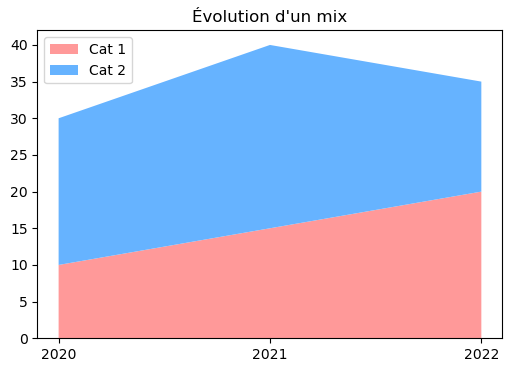

In [14]:
# Code Python

annees = [2020, 2021, 2022]
cat1 = [10, 15, 20]
cat2 = [20, 25, 15]
plt.figure(figsize=(6, 4))
plt.stackplot(annees, cat1, cat2, labels=['Cat 1', 'Cat 2'], colors=['#ff9999', '#66b3ff'])
plt.legend(loc='upper left')
plt.title("Évolution d'un mix")
plt.xticks(annees)
plt.show()

## 5. Visualiser une composition (Parties d'un tout)
### 5.1. Diagramme en secteurs (Camembert / Pie Chart)

- **Variables impliquées** : une variable *qualitative nominale* (les catégories), et une variable *quantitative continue* positive (Les parts).

- **Cas d'utilisation** : visualiser des proportions simples (2 à 4 catégories maximum).

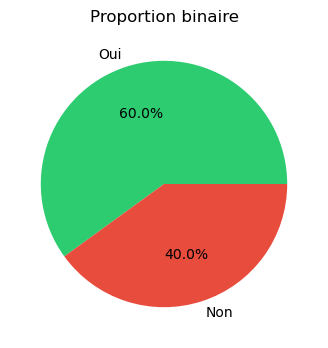

In [15]:
# Code Python

parts = [60, 40]
labels = ['Oui', 'Non']
plt.figure(figsize=(4, 4))
plt.pie(parts, labels=labels, autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'])
plt.title("Proportion binaire")
plt.show()

### 5.2. Graphique en Anneau (Donut Chart)

- **Variables impliquées** : une variable *qualitative nominale*, et une variable *quantitative continue* positive.

- **Cas d'utilisation** : Identique au camembert, mais l'espace central permet d'alléger le visuel ou d'y insérer le total chiffré.

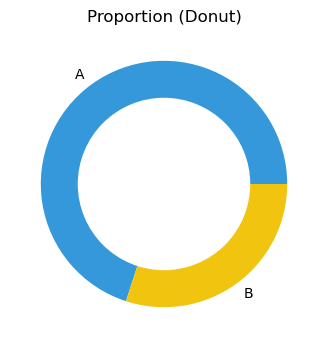

In [16]:
# Code Python

plt.figure(figsize=(4, 4))
plt.pie([70, 30], labels=['A', 'B'], colors=['#3498db', '#f1c40f'])
centre = plt.Circle((0,0), 0.70, fc='white')
plt.gcf().gca().add_artist(centre)
plt.title("Proportion (Donut)")
plt.show()

### 5.3. Diagramme à Barres Empilées (Stacked Bar Chart)

- **Variables impliquées** : 2 variables *qualitatives nominales* (Catégorie principale X, et Sous-catégories empilées) et une variable *quantitative*.

- **Cas d'utilisation** : comparer la composition de plusieurs totaux côte à côte.

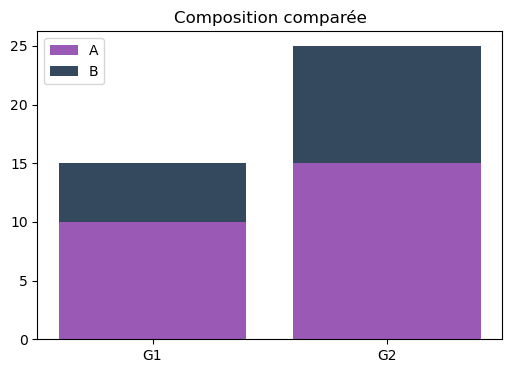

In [17]:
# Code Python

groupes = ['G1', 'G2']
sous_cat_A = [10, 15]
sous_cat_B = [5, 10]

plt.figure(figsize=(6, 4))
plt.bar(groupes, sous_cat_A, label='A', color='#9b59b6')
plt.bar(groupes, sous_cat_B, bottom=sous_cat_A, label='B', color='#34495e')
plt.legend()
plt.title("Composition comparée")
plt.show()

### 5.4. Treemap (Carte à cases)

- **Variables impliquées** : une à N variables *qualitatives nominales* (Hiérarchie) et une variable *quantitative* (Surface du rectangle).

- **Cas d'utilisation** : afficher des proportions pour un très grand nombre de catégories ou des données hiérarchiques imbriquées (impossible avec un camembert).

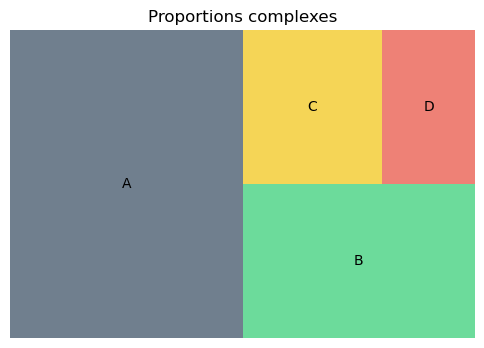

In [18]:
# Code Python

tailles = [50, 25, 15, 10]
labels = ['A', 'B', 'C', 'D']
couleurs = ['#34495e', '#2ecc71', '#f1c40f', '#e74c3c'] 
plt.figure(figsize=(6, 4))
squarify.plot(sizes=tailles, label=labels, color=couleurs, alpha=0.7)
plt.axis('off')
plt.title("Proportions complexes")
plt.show()

## 6. Visualiser des données spatiales (Cartographie)
### 6.1. La Carte choroplèthe (Choropleth Map)

- **Variables impliquées** : une variable *spatiale* (noms de pays, codes ISO, ou frontières géographiques), et une variable *quantitative continue* (pour l'intensité de la couleur).

- **Cas d'utilisation** : colorer des régions, des départements ou des pays en fonction d'une métrique (ex: densité de population, taux de chômage, résultat à une élection).


In [19]:
# Code Python

pio.renderers.default = "iframe"

# Chargement d'un jeu de données intégré à Plotly (Données mondiales de 2007)
df = px.data.gapminder().query("year == 2007")

# Création de la carte choroplèthe
fig = px.choropleth(
    df, 
    locations="iso_alpha", # Les codes pays (ex: FRA, USA)
    color="lifeExp",       # La variable à visualiser (Espérance de vie)
    hover_name="country",  # Texte au survol
    color_continuous_scale=px.colors.sequential.Teal,
    title="Espérance de vie par pays en 2007 (Carte Choroplèthe)"
)

# Affichage (Ouvre une carte interactive dans le navigateur)
fig.show()

### 6.2. La Carte à bulles / Symboles proportionnels (Bubble Map)

- **Variables impliquées** : 2 variables *spatiales* (Latitude et Longitude, ou codes lieux), et une variable *quantitative* (Taille de la bulle), avec éventuellement une variable *qualitative* (Couleur).

- **Cas d'utilisation** : placer des points précis sur une carte pour montrer la répartition géographique ET le volume d'un phénomène (ex: taille des villes par nombre d'habitants, épicentres de séismes par magnitude). C'est souvent préférable à la carte choroplèthe quand la superficie du pays risque de fausser l'importance visuelle de la donnée (ex: la Russie prend beaucoup de place visuellement, même pour une métrique faible).

In [20]:
# Code Python

df = px.data.gapminder().query("year == 2007")

fig = px.scatter_geo(
    df, 
    locations="iso_alpha", 
    color="continent",          # Une couleur par continent (Qualitatif)
    hover_name="country", 
    size="pop",                 # Taille selon la population (Quantitatif)
    projection="natural earth", # Type de projection cartographique
    title="Population mondiale (Carte à Bulles Proportionnelles)"
)

fig.show()

### 6.3. La Carte de Densité ou carte de Chaleur Spatiale (Spatial Heatmap)

- **Variables impliquées** : 2 variables *spatiales continues* (Latitude, Longitude), et une variable *quantitative* (Densité de points ou intensité).

- **Cas d'utilisation** : visualiser des zones de forte concentration géographique (les fameux « points chauds » ou hotspots). Très utilisé avec des cartes type Google Maps (fonds de tuiles routières) pour analyser des accidents de la route, des commandes de livraison ou des trajets en trottinette dans une ville.

    

In [21]:
# Code Python

# Simulation de coordonnées (ex: livraisons dans le centre de Paris)
np.random.seed(42)
df_paris = pd.DataFrame({
    'lat': np.random.normal(48.8566, 0.01, 500),
    'lon': np.random.normal(2.3522, 0.01, 500),
    'intensite': np.random.randint(1, 10, 500)
})

fig = px.density_map(
    df_paris, lat='lat', lon='lon', z='intensite', radius=10,
    center=dict(lat=48.8566, lon=2.3522), zoom=12,
    map_style="carto-positron", # Fond de carte de type rue/ville
    title="Concentration des livraisons (Carte de Chaleur Spatiale)"
)

fig.show(renderer="browser")

### 6.4. La Carte de Flux / Réseaux Géographiques (Flow Map)

- **Variables impliquées** : 4 variables *spatiales* (Latitude/Longitude d'origine + Latitude/Longitude de destination), et une variable *quantitative* (Épaisseur ou couleur du trait représentant le volume).

- **Cas d'utilisation** : visualiser des mouvements ou des échanges entre des lieux géographiques (ex: routes aériennes, commerce international de marchandises, migrations).

In [22]:
# Code Python

# Données simulées : Trafic aérien (vols) au départ de Paris vers d'autres métropoles
lat_paris, lon_paris = 48.8566, 2.3522

# Liste des destinations avec leurs coordonnées et le volume de passagers
destinations = [
    {"ville": "New York", "lat": 40.7128, "lon": -74.0060, "volume": 1500},
    {"ville": "Tokyo", "lat": 35.6895, "lon": 139.6917, "volume": 800},
    {"ville": "Rio de Janeiro", "lat": -22.9068, "lon": -43.1729, "volume": 500},
    {"ville": "Dubaï", "lat": 25.2048, "lon": 55.2708, "volume": 1200}
]

fig = go.Figure()

# 1. Ajout des lignes de flux (arcs)
for dest in destinations:
    fig.add_trace(go.Scattergeo(
        lon = [lon_paris, dest["lon"]],
        lat = [lat_paris, dest["lat"]],
        mode = 'lines',
        # L'épaisseur de la ligne est proportionnelle au volume
        line = dict(width = dest["volume"] / 300, color = '#e74c3c'), 
        opacity = 0.7,
        name = f'Paris -> {dest["ville"]}'
    ))

# 2. Ajout des marqueurs pour les villes (Points)
lats = [lat_paris] + [d["lat"] for d in destinations]
lons = [lon_paris] + [d["lon"] for d in destinations]
villes = ["Paris"] + [d["ville"] for d in destinations]

fig.add_trace(go.Scattergeo(
    lon = lons,
    lat = lats,
    hoverinfo = 'text',
    text = villes,
    mode = 'markers+text',
    textposition="bottom center",
    marker = dict(size = 8, color = '#2c3e50')
))

# 3. Personnalisation de la carte
fig.update_layout(
    title_text = "Trafic aérien au départ de Paris (Carte de Flux)",
    showlegend = False,
    geo = dict(
        projection_type = 'orthographic', # Donne un aspect globe 3D à la carte
        showland = True,
        landcolor = 'rgb(243, 243, 243)',
        countrycolor = 'rgb(204, 204, 204)',
    )
)

fig.show(renderer="browser")

## 7. Modéliser des flux et des réseaux
### 7.1. Le Diagramme de Sankey (Sankey Diagram)

- **Variables impliquées** : 2 variables *qualitatives nominales* (Nœud Source et Nœud Cible), et une variable *quantitative* (Volume du flux dictant l'épaisseur de la bande).

- **Cas d'utilisation** : analyser des parcours utilisateurs sur un site web, des transferts de budget, ou des bilans énergétiques (comment l'énergie est produite puis consommée ou perdue).

In [23]:
# Code Python

# Les nœuds (0: Accueil, 1: Produit, 2: Panier, 3: Achat, 4: Quitte)
# Les sources et cibles sont les index des nœuds
fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 15,
      thickness = 20,
      line = dict(color = "black", width = 0.5),
      label = ["Accueil", "Page Produit", "Panier", "Achat Validé", "Abandon"],
      color = "blue"
    ),
    link = dict(
      source = [0, 0, 1, 1, 2, 2], # Index de départ
      target = [1, 4, 2, 4, 3, 4], # Index d'arrivée
      value =  [80, 20, 50, 30, 40, 10] # Volume du flux
  ))])

fig.update_layout(title_text="Parcours Utilisateur (Sankey)", font_size=10)
fig.show()

### 7.2. Le Graphe de Réseau (Node-Link / Network Graph)

- **Variables impliquées** : N variables *qualitatives* (Les Nœuds/Entités), et *qualitatives/quantitatives* (Les Liens/Arêtes reliant les nœuds).

- **Cas d'utilisation** : visualiser des interconnexions (réseaux sociaux, détection de fraude en banque, infrastructures informatiques).


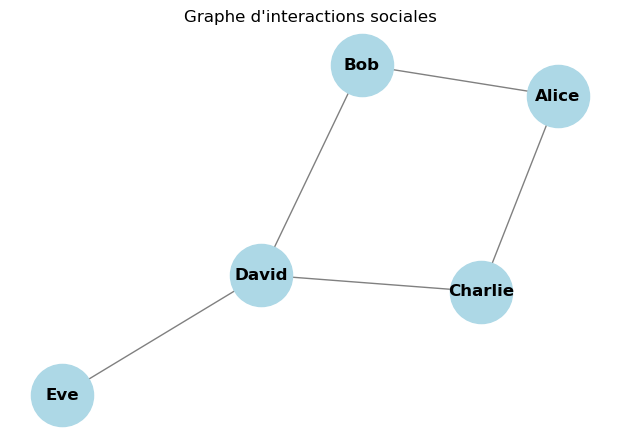

In [24]:
# Code Python

G = nx.Graph()
# Ajout de liens entre des entités
liens = [('Alice', 'Bob'), ('Alice', 'Charlie'), ('Bob', 'David'), ('Charlie', 'David'), ('David', 'Eve')]
G.add_edges_from(liens)

plt.figure(figsize=(6, 4))
# Dessin du réseau avec un algorithme de force (Spring layout)
nx.draw(G, with_labels=True, node_color='lightblue', node_size=2000, edge_color='gray', font_weight='bold')
plt.title("Graphe d'interactions sociales")
plt.show()

## 8. Modéliser des hiérarchies multicouches

### 8.1. Le Graphique Rayonnant (Sunburst Chart)

- **Variables impliquées** : N variables *qualitatives nominales* (Niveaux de la hiérarchie), et une variable *quantitative* (Surface/Angle).
    
- **Cas d'utilisation** : C'est l'alternative moderne et circulaire au Treemap. Idéal pour explorer des données imbriquées (ex: Chiffre d'affaires $\rightarrow$ par Continent $\rightarrow$ par Pays $\rightarrow$ par Catégorie de produit). Le centre représente la racine, et on s'éloigne vers le détail.

In [25]:
# Code Python

# Données hiérarchiques fictives
df = pd.DataFrame(dict(
    character=["Monde", "Europe", "Asie", "France", "Allemagne", "Chine", "Japon"],
    parent=["", "Monde", "Monde", "Europe", "Europe", "Asie", "Asie"],
    value=[100, 40, 60, 25, 15, 40, 20])
)

fig = px.sunburst(df, names='character', parents='parent', values='value', title="Répartition hiérarchique (Sunburst)")
# fig.show()

## 9. Visualisations spécialisées (Business, Finance & RH)

### 9.1. Le Diagramme en Cascade (Waterfall Chart)

- **Variables impliquées** : une variable *qualitative* (Étapes ou Temps), et une variable *quantitative* (Valeurs positives ou négatives).

- **Cas d'utilisation** : Décomposer comment on passe d'une valeur initiale à une valeur finale à travers une série d'ajustements (ex: Chiffre d'affaires brut $\rightarrow$ - Coûts $\rightarrow$ - Taxes $\rightarrow$ + Aides $\rightarrow$ Bénéfice net).

In [26]:
# Code Python:

fig = go.Figure(go.Waterfall(
    name = "20", orientation = "v",
    measure = ["absolute", "relative", "relative", "relative", "total"],
    x = ["Revenu Brut", "Coûts de prod.", "Taxes", "Subventions", "Revenu Net"],
    textposition = "outside",
    text = ["1000", "-300", "-200", "50", "550"],
    y = [1000, -300, -200, 50, 550],
    connector = {"line":{"color":"rgb(63, 63, 63)"}}
))
fig.update_layout(title="Décomposition du bilan financier (Waterfall)")
fig.show()

### 9.2. Le Graphique en Radar / Toile d'araignée (Radar / Spider Chart)

- **Variables impliquées** : N variables *qualitatives nominales* (Les axes du radar), et une variable *quantitative continue* (Le score sur l'axe), et une variable *qualitative* (La catégorie à laquelle appartient le polygone).

- **Cas d'utilisation** : Comparer un ou plusieurs profils sur de multiples dimensions qualitatives non corrélées (ex: évaluation des compétences d'un candidat, statistiques d'un personnage de jeu vidéo, caractéristiques d'un vin).

In [27]:
import plotly.graph_objects as go

categories = ['Communication', 'Technique', 'Management', 'Vente', 'Créativité']

fig = go.Figure()
fig.add_trace(go.Scatterpolar(
      r=[4, 5, 2, 3, 5],
      theta=categories,
      fill='toself',
      name='Candidat A'
))
fig.add_trace(go.Scatterpolar(
      r=[3, 2, 5, 4, 3],
      theta=categories,
      fill='toself',
      name='Candidat B'
))

fig.update_layout(polar=dict(radialaxis=dict(visible=True, range=[0, 5])), title="Profil de compétences (Radar)")
fig.show()

### 9.3. Le Graphique en Entonnoir (Funnel Chart)

- **Variables impliquées** : une variable *qualitative ordinale* (Les étapes séquentielles), et une variable *quantitative décroissante* (Le volume d'utilisateurs/montants).

- **Cas d'utilisation** : Analyser le taux de déperdition (churn) ou de conversion à chaque étape d'un processus linéaire (ex: Visiteurs site $\rightarrow$ Inscrits $\rightarrow$ Ajout panier $\rightarrow$ Clients payants).Code Python :

In [28]:
# Code Python
data = dict(
    etapes=["Visiteurs", "Inscrits", "Essais Gratuits", "Abonnés Payants"],
    volume=[10000, 4000, 1500, 300]
)
df = pd.DataFrame(data)

fig = px.funnel(df, x='volume', y='etapes', title="Tunnel de conversion (Funnel)")
fig.show()

### 9.4. Le Graphique en Chandelier (Candlestick Chart)

- **Variables impliquées** : une variable *quantitative ordonnée* (Temps), et 4 variables *quantitatives* (Ouverture, Fermeture, Plus Haut, Plus Bas).

- **Cas d'utilisation** : Exclusivement utilisé pour l'analyse technique des marchés financiers (bourse, cryptomonnaies) pour voir la volatilité au sein d'une même journée.

In [29]:
# Code Python

df = pd.DataFrame({
    'Date': ['2023-10-01', '2023-10-02', '2023-10-03', '2023-10-04'],
    'Open': [100, 105, 103, 110],
    'High': [110, 108, 112, 115],
    'Low': [95, 102, 100, 108],
    'Close': [105, 103, 110, 114]
})

fig = go.Figure(data=[go.Candlestick(x=df['Date'],
                open=df['Open'], high=df['High'],
                low=df['Low'], close=df['Close'])])

fig.update_layout(title="Cours de la bourse (Candlestick)")
# fig.show()



# Application Pratique en Python (10 Cas d'Étude)

Pour chaque cas, nous confrontons l'approche naïve (souvent générée par défaut) à l'approche optimisée.

## Cas 1 : Le diagramme en barres (Comparaison catégorielle)
**Défaut :** 
- Libellés sur l'axe X inclinés 
- Couleurs aléatoires inutiles. (Les couleurs n'apportent pas plus d'informations)
- Les différents axes ne sont pas nommés

**Amélioration :** 
-
Pivoter en barres horizontales (Les différentes catégories sont désormais lisibles), utiliser une couleur unie.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

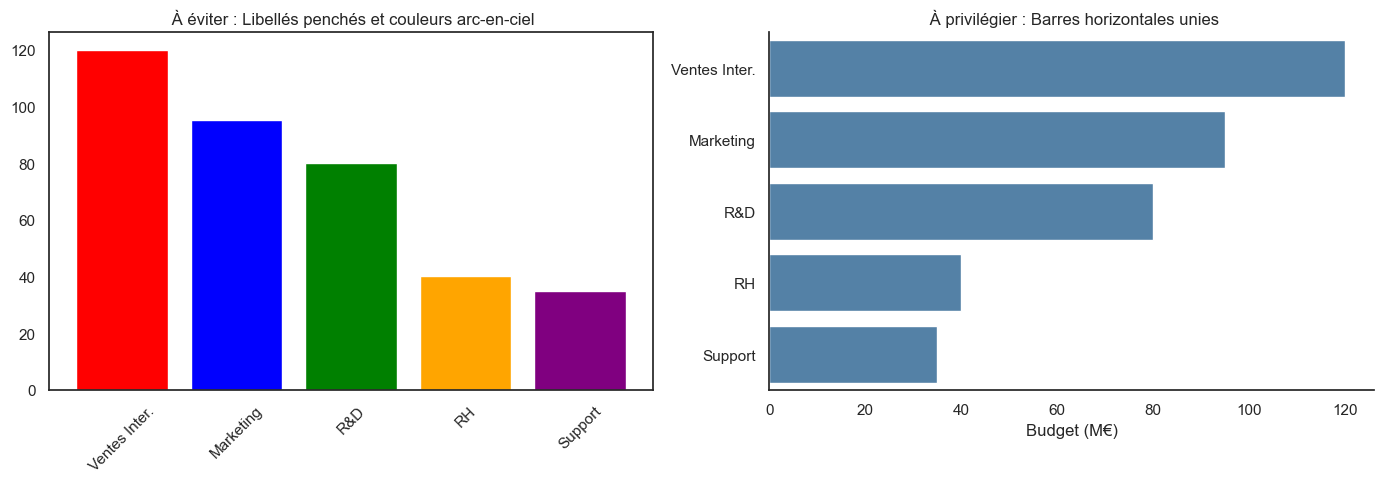

In [5]:
categories = ['Ventes Inter.', 'Marketing', 'R&D', 'RH', 'Support']
budget = [120, 95, 80, 40, 35]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Erreur
ax1.bar(categories, budget, color=['red', 'blue', 'green', 'orange', 'purple'])
ax1.tick_params(axis='x', rotation=45)
ax1.set_title(" À éviter : Libellés penchés et couleurs arc-en-ciel")

# Optimisation
sns.barplot(x=budget, y=categories, color='steelblue', ax=ax2)
ax2.set_title(" À privilégier : Barres horizontales unies")
ax2.set_xlabel("Budget (M€)")
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()

## Cas 2 : La composition (Camembert vs Barres)
**Défaut :** Camembert avec effet 3D, difficile de comparer des parts similaires.

**Amélioration :** Barres horizontales empilées à 100%.

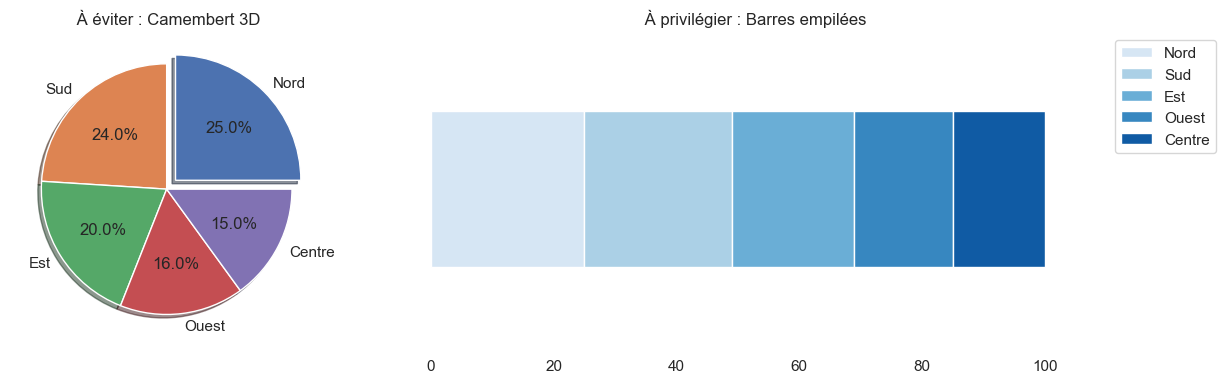

In [6]:

parts = [25, 24, 20, 16, 15]
labels = ['Nord', 'Sud', 'Est', 'Ouest', 'Centre']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Erreur
ax1.pie(parts, labels=labels, autopct='%1.1f%%', shadow=True, explode=(0.1, 0, 0, 0, 0))
ax1.set_title(" À éviter : Camembert 3D")

# Optimisation
df = pd.DataFrame({'Part': parts}, index=labels)
df.T.plot(kind='barh', stacked=True, color=sns.color_palette("Blues", 5), ax=ax2)
ax2.set_title(" À privilégier : Barres empilées")
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.set_yticks([])
sns.despine(ax=ax2, left=True, bottom=True)

plt.tight_layout()
plt.show()

## Cas 3 : Le nuage de points (Corrélation)
**Défaut :** Sur-représentation (Overplotting) masquant la densité.

**Amélioration :** Utiliser la transparence (`alpha`) et réduire la taille des points.

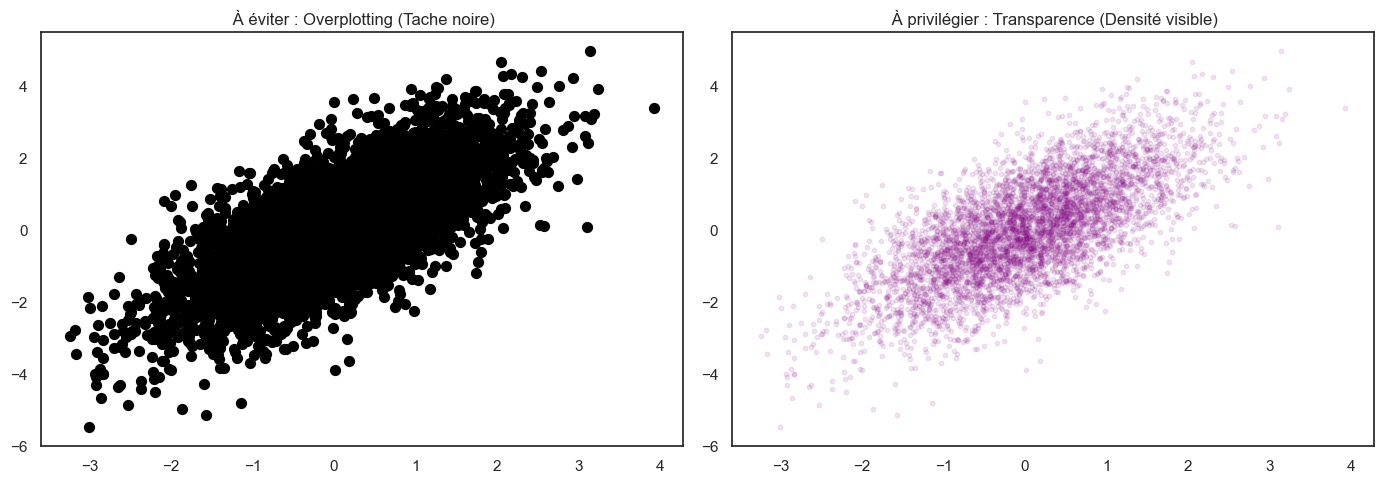

In [7]:
#| label: cas-4
x = np.random.normal(0, 1, 5000)
y = x + np.random.normal(0, 1, 5000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Erreur
ax1.scatter(x, y, s=50, color='black')
ax1.set_title(" À éviter : Overplotting (Tache noire)")

# Optimisation
ax2.scatter(x, y, alpha=0.1, s=10, color='purple')
ax2.set_title(" À privilégier : Transparence (Densité visible)")

plt.tight_layout()
plt.show()

## Cas 4 : Comparaison de distributions
**Défaut :** Le Boxplot masque la forme réelle de la distribution (ex: bimodale).

**Amélioration :** Le Violin Plot.

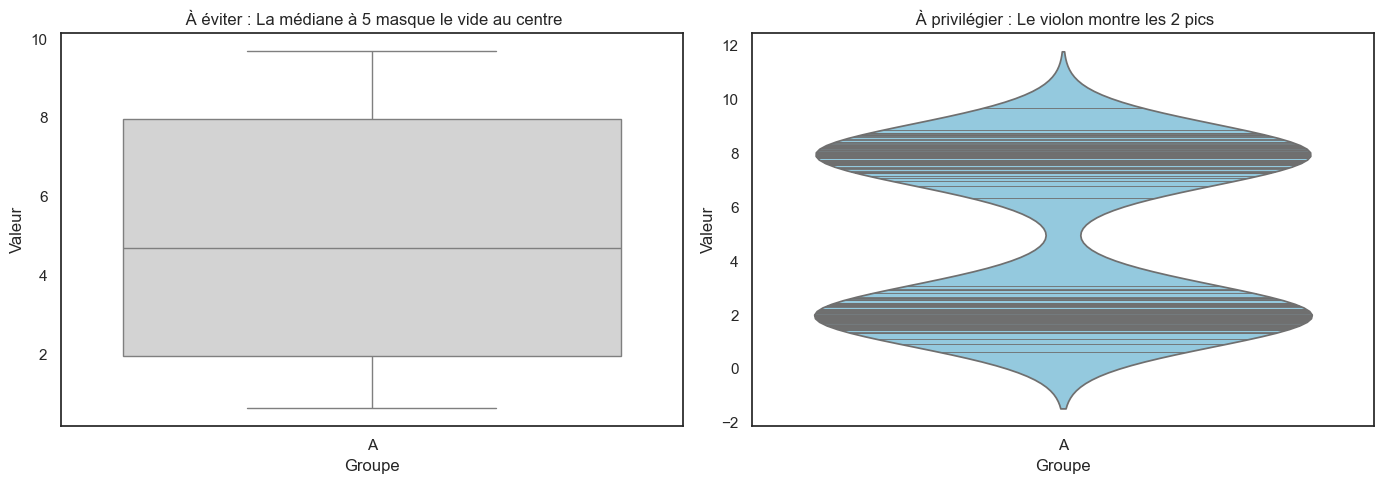

In [9]:
#| label: cas-6
dist_bimodale = np.concatenate([np.random.normal(2, 0.5, 100), np.random.normal(8, 0.5, 100)])
df_dist = pd.DataFrame({'Groupe': ['A']*200, 'Valeur': dist_bimodale})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Erreur
sns.boxplot(x='Groupe', y='Valeur', data=df_dist, ax=ax1, color='lightgray')
ax1.set_title(" À éviter : La médiane à 5 masque le vide au centre")

# Optimisation
sns.violinplot(x='Groupe', y='Valeur', data=df_dist, ax=ax2, color='skyblue', inner='stick')
ax2.set_title(" À privilégier : Le violon montre les 2 pics")

plt.tight_layout()
plt.show()

## Cas 5 : Matrice de corrélation
**Défaut :** Matrice complète redondante, couleurs non divergentes.

**Amélioration :** Masque triangulaire, palette divergente centrée sur zéro.

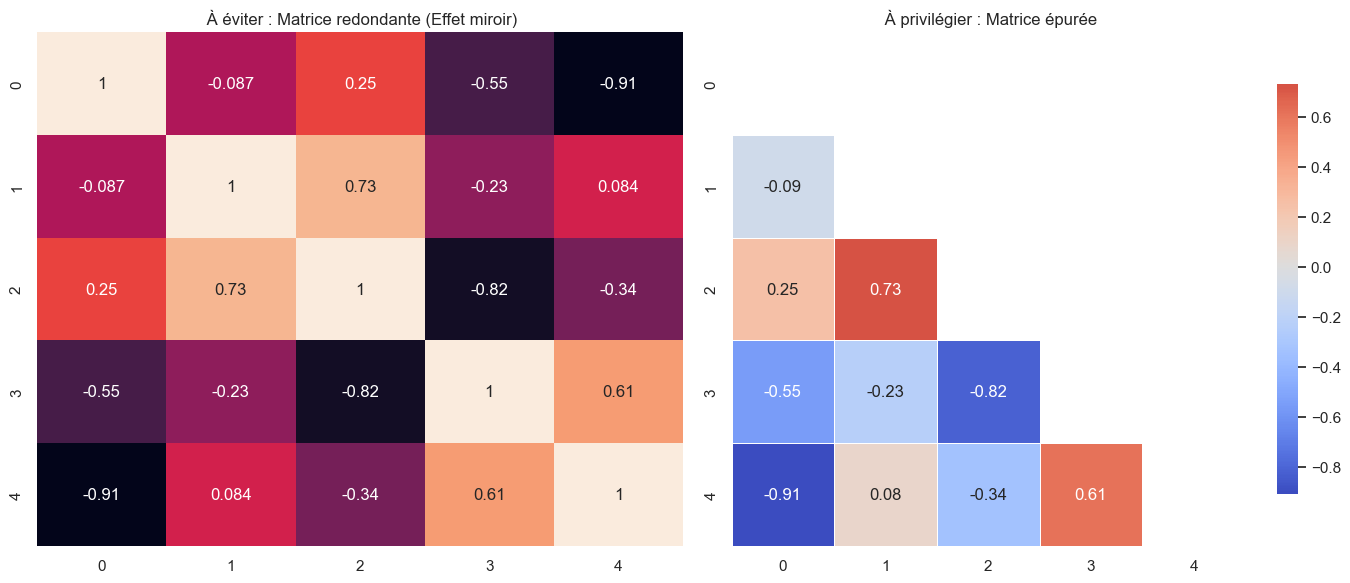

In [12]:
corr = pd.DataFrame(np.random.randn(5, 5)).corr()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Erreur
sns.heatmap(corr, annot=True, ax=ax1, cbar=False)
ax1.set_title(" À éviter : Matrice redondante (Effet miroir)")

# Optimisation
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=True, fmt=".2f", 
            square=True, linewidths=.5, ax=ax2, cbar_kws={"shrink": .8})
ax2.set_title(" À privilégier : Matrice épurée")

plt.tight_layout()
plt.show()

## Cas 6 : Le diagramme à bulles
**Défaut :** Mapper la variable quantitative sur le *rayon* fausse l'aire de façon quadratique.

**Amélioration :** Mapper sur l'*aire* (paramètre `s` dans Matplotlib).

Dans un diagramme à bulles, l’œil compare des surfaces. Si on agrandit le rayon au lieu de la surface, une valeur deux fois plus grande paraît quatre fois plus grosse. Il faut donc toujours que ce soit la surface de la bulle qui soit proportionnelle à la valeur

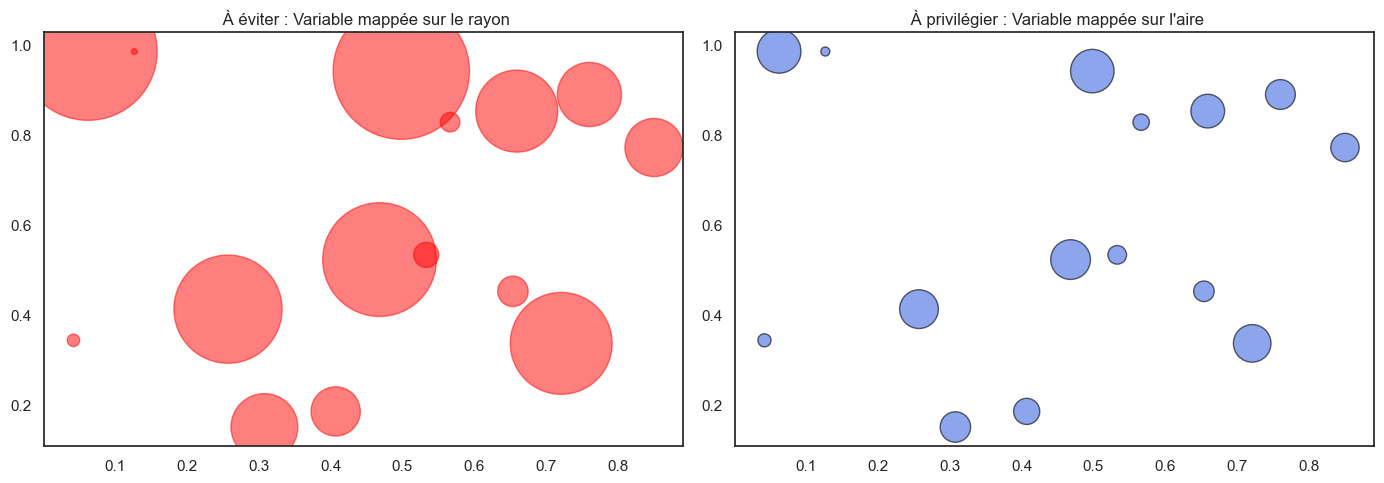

In [14]:
x_b = np.random.rand(15)
y_b = np.random.rand(15)
z_b = np.random.rand(15) * 10

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Erreur (Simulation du mappage par rayon)
ax1.scatter(x_b, y_b, s=(z_b*10)**2, color='red', alpha=0.5) 
ax1.set_title(" À éviter : Variable mappée sur le rayon")

# Optimisation
ax2.scatter(x_b, y_b, s=z_b*100, color='royalblue', alpha=0.6, edgecolors="black")
ax2.set_title(" À privilégier : Variable mappée sur l'aire")

plt.tight_layout()
plt.show()

## Cas 7 : Représentation d'une proportion complexe
**Défaut :** Des diagrammes en barres très denses et lourds en encre.

**Amélioration :** Le Dot Plot (Diagramme à points) offre un ratio données/encre optimal.

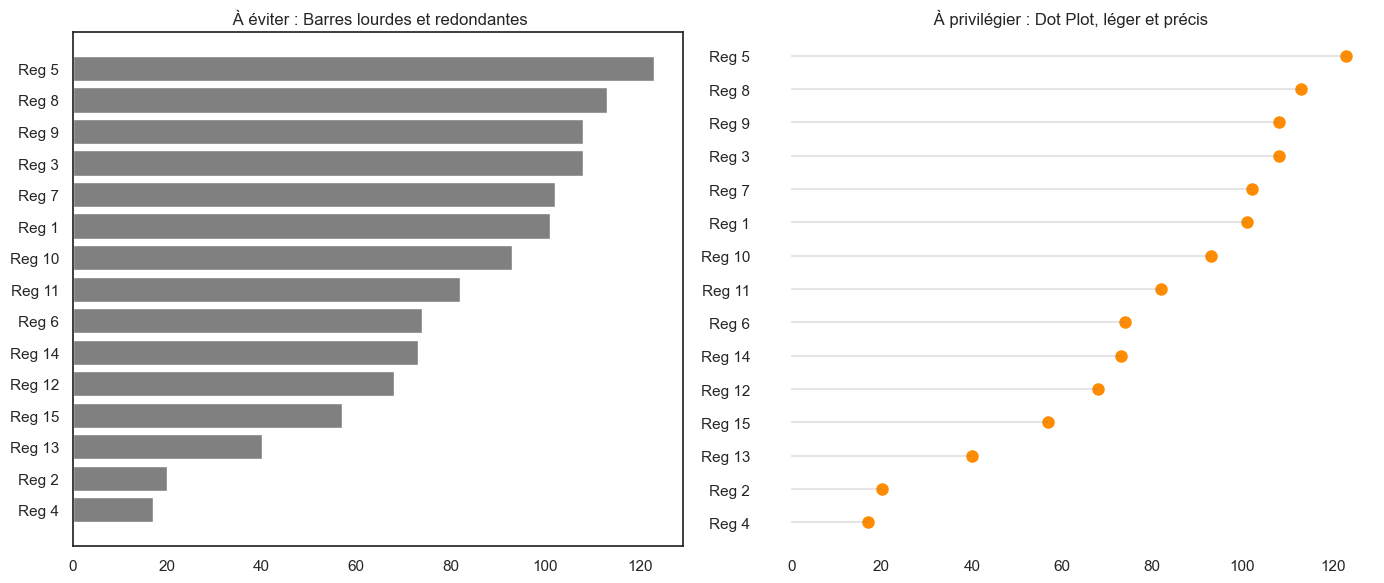

In [15]:
#| label: cas-10
regions = ['Reg ' + str(i) for i in range(1, 16)]
valeurs = np.random.randint(10, 150, 15)
df_pop = pd.DataFrame({'Région': regions, 'Valeur': valeurs}).sort_values('Valeur')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Erreur
ax1.barh(df_pop['Région'], df_pop['Valeur'], color='gray')
ax1.set_title(" À éviter : Barres lourdes et redondantes")

# Optimisation
ax2.plot(df_pop['Valeur'], df_pop['Région'], 'o', markersize=8, color='darkorange')
for i in range(len(df_pop)):
    ax2.hlines(y=df_pop['Région'].iloc[i], xmin=0, xmax=df_pop['Valeur'].iloc[i], color='grey', alpha=0.2)
ax2.set_title(" À privilégier : Dot Plot, léger et précis")
sns.despine(ax=ax2, left=True, bottom=True)

plt.tight_layout()
plt.show()

## Cas 8 : la courbe à axe inversé (Reuters, 2014)
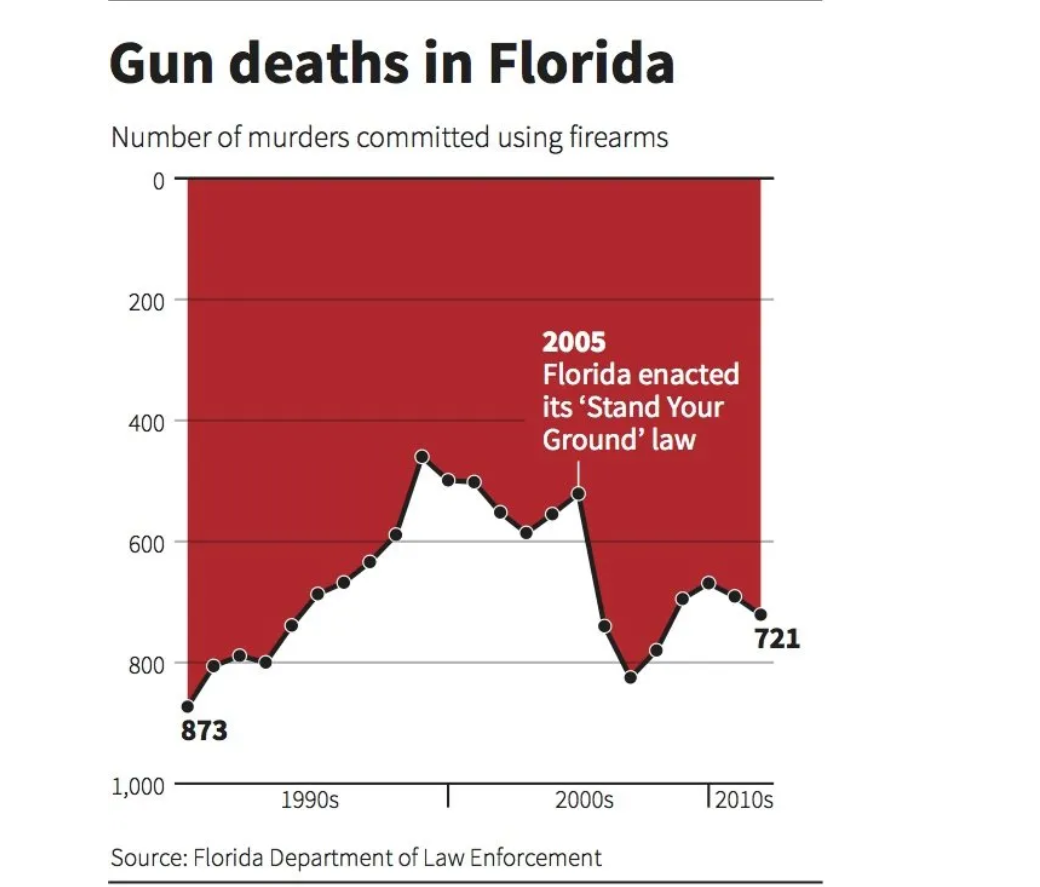
- On voudrait ici montrer l’évolution du nombre d’homicides par arme à feu en Floride de 1990 à 2012, et l’effet possible de la loi « Stand Your Ground » de 2005.
- On distingue 2 variables.
l’année : quantitative (temporelle) ;
le nombre d’homicides : quantitative .
Pour une évolution dans le temps, la courbe est le bon choix. Le problème vient de la façon dont elle est présentée.
#### Défauts :
- Axe Y inversé : contraire à la convention (plus haut = plus grand). L’œil lit une baisse là où il y a une hausse.
- Remplissage rouge au-dessus de la courbe on lit la frontière rouge/blanc comme une courbe qui descend.
- Pas de titre sur l’axe Y, et un titre neutre qui ne guide pas le lecteur.

#### Améliorations :

- Axe Y dans le sens normal, partant de 0 ;
- Courbe simple, sans remplissage ;
- Ligne en pointillés pour marquer 2005, avec les valeurs clés annotées ;
- Titre qui énonce le message.

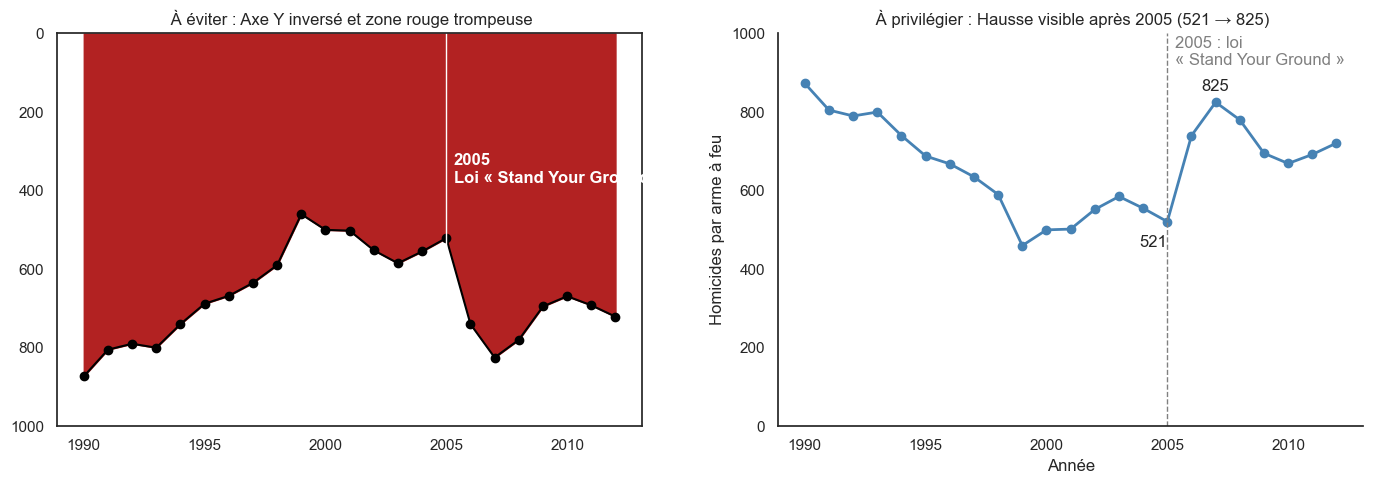

In [10]:
# Valeurs relevées sur le graphique Reuters (2014), source : Florida Department of Law Enforcement
annees = list(range(1990, 2013))
morts = [873, 805, 790, 800, 740, 688, 668, 635, 590, 460, 500, 502,
         552, 585, 555, 521, 740, 825, 780, 695, 669, 692, 721]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Erreur
ax1.plot(annees, morts, color='black', marker='o')
ax1.fill_between(annees, morts, 0, color='firebrick')
ax1.set_ylim(1000, 0)  # axe inversé : 0 en haut
ax1.axvline(2005, color='white', linewidth=1)
ax1.text(2005.3, 380, "2005\nLoi « Stand Your Ground »", color='white', fontweight='bold')
ax1.set_title(" À éviter : Axe Y inversé et zone rouge trompeuse")

# Optimisation
ax2.plot(annees, morts, color='steelblue', marker='o', linewidth=2)
ax2.set_ylim(0, 1000)
ax2.axvline(2005, color='grey', linestyle='--', linewidth=1)
ax2.text(2005.3, 920, "2005 : loi\n« Stand Your Ground »", color='grey')
ax2.annotate("521", (2005, 521), textcoords="offset points", xytext=(-10, -18), ha='center')
ax2.annotate("825", (2007, 825), textcoords="offset points", xytext=(0, 8), ha='center')
ax2.set_title(" À privilégier : Hausse visible après 2005 (521 → 825)")
ax2.set_xlabel("Année")
ax2.set_ylabel("Homicides par arme à feu")
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()

## Cas 9 le camembert à 193 % (Fox News, 2009)
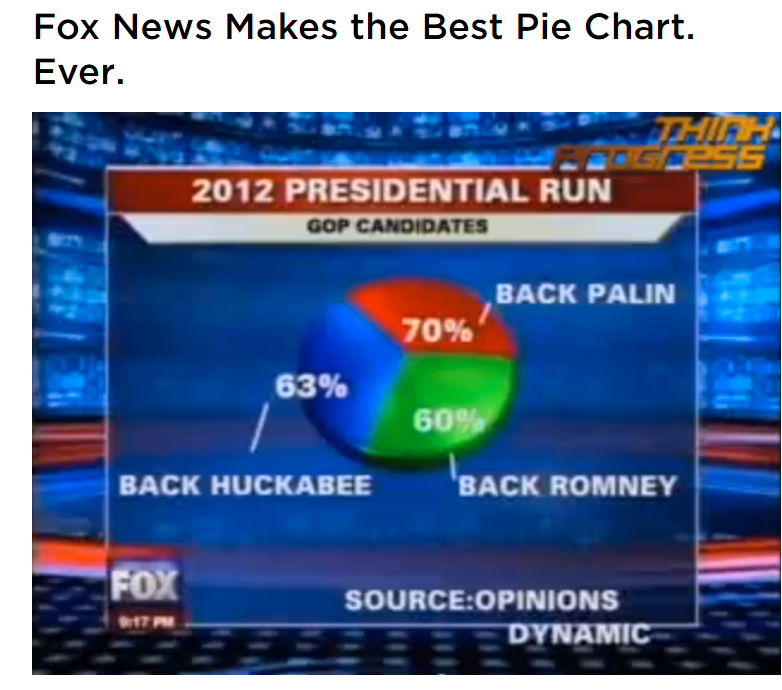

On voudrait voir quel candidat républicain est le plus apprécié en vue de l’élection présidentielle de 2012 ?
On distingue 2 variables.
- le candidat : qualitative nominale (Palin, Huckabee, Romney) ;
- le pourcentage d’opinions favorables : quantitative. Chaque pourcentage se calcule sur l’ensemble des personnes interrogées, indépendamment des deux autres.
#### Défauts :
- Mauvais choix de graphique : un camembert suppose des parts dont le total fait 100 %. Ce n’est pas le cas ici.
- Somme de 193 % : c’est mathématiquement impossible pour un camembert. Les surfaces des parts ne correspondent pas aux chiffres affichés.
- Couleurs vives sans signification (rouge, vert, bleu), sur un fond chargé.
- Titre flou : « 2012 Presidential Run » ne dit pas ce que mesurent les pourcentages.
#### Améliorations :

- Barres horizontales triées, sur une échelle de 0 à 100 % ;
- Une seule couleur, avec la valeur affichée au bout de chaque barre ;
- Un titre qui précise la mesure : « Part des républicains ayant une opinion favorable de chaque candidat ».

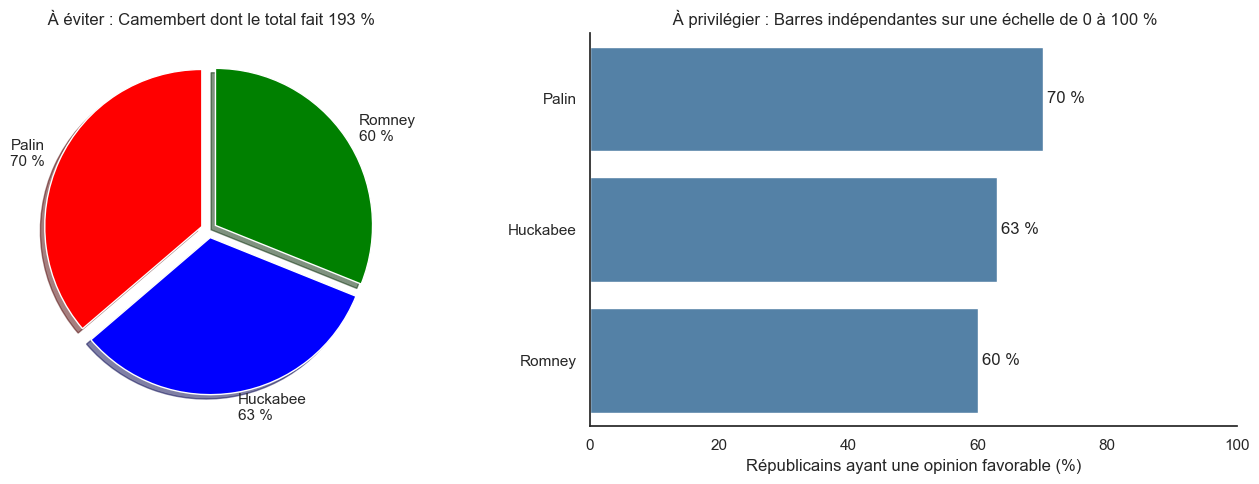

In [11]:
#| label: cas-3
# Sondage Fox News / Opinion Dynamics (2009) : opinions favorables chez les républicains
candidats = ['Palin', 'Huckabee', 'Romney']
favorable = [70, 63, 60]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Erreur
ax1.pie(favorable, labels=[f"{c}\n{v} %" for c, v in zip(candidats, favorable)],
        colors=['red', 'blue', 'green'], explode=[0.05, 0.05, 0.05],
        shadow=True, startangle=90)
ax1.set_title(" À éviter : Camembert dont le total fait 193 %")

# Optimisation
sns.barplot(x=favorable, y=candidats, color='steelblue', ax=ax2)
ax2.bar_label(ax2.containers[0], fmt='%d %%', padding=3)
ax2.set_xlim(0, 100)
ax2.set_title(" À privilégier : Barres indépendantes sur une échelle de 0 à 100 %")
ax2.set_xlabel("Républicains ayant une opinion favorable (%)")
ax2.set_ylabel("")
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()

# CAS 10 Fox News, taux de chômage 2011
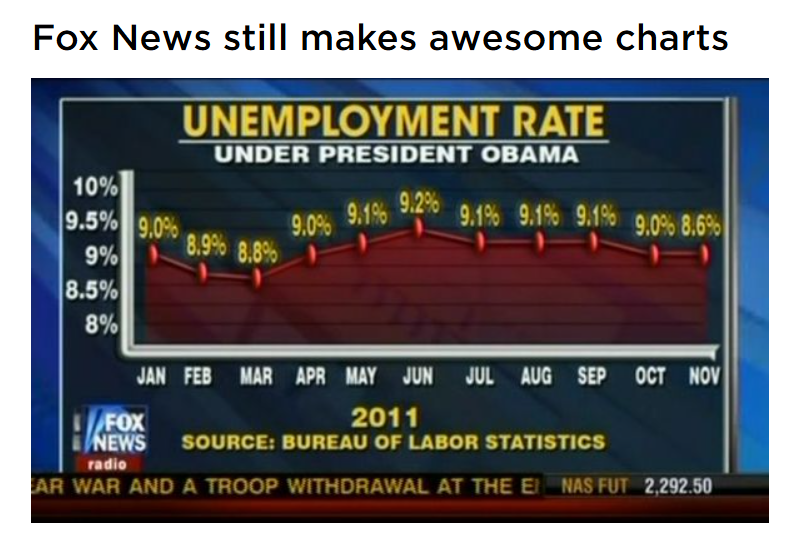

L'intention est de montrer l’évolution du taux de chômage aux États-Unis de janvier à novembre 2011.

On ditingue 2 variables.
- le mois : variable temporelle (qualitative ordinale ici, 11 mois) ;
- le taux de chômage : quantitative continue, en %.
La courbe est le bon choix pour une évolution dans le temps.

#### Défauts :

- Point placé à une hauteur fausse : 8,6 % est dessiné au niveau de 9 %. Le graphique contredit sa propre étiquette.
- Remplissage rouge sous la courbe : une surface colorée suggère une quantité mesurée depuis zéro, alors que l’axe commence à 8 %. Il amplifie aussi visuellement les variations.
- Titre orienté (« sous le président Obama ») : il associe les chiffres à une personne au lieu de décrire les données.
- Étiquettes surchargées : 11 valeurs en jaune sur fond rouge et bleu, difficiles à lire.

#### Améliorations :

- chaque point à sa vraie position ;
- une courbe simple, sans remplissage ;
- seules les valeurs clés sont annotées, avec la baisse de novembre mise en valeur ;
- un titre neutre et descriptif, avec la source.

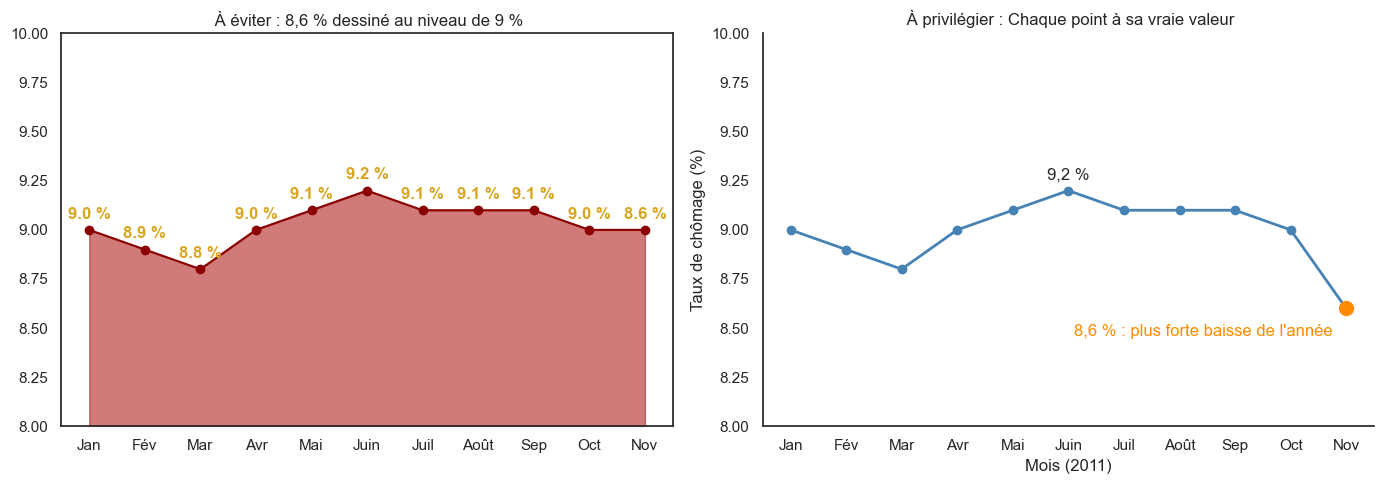

In [16]:
#| label: cas-chomage
# Taux de chômage aux États-Unis en 2011, source : Bureau of Labor Statistics (valeurs affichées par Fox News)
mois = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov']
taux = [9.0, 8.9, 8.8, 9.0, 9.1, 9.2, 9.1, 9.1, 9.1, 9.0, 8.6]
taux_dessine = taux[:-1] + [9.0]  # Fox a placé 8,6 % au niveau de 9,0 %

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Erreur
ax1.plot(mois, taux_dessine, color='darkred', marker='o')
ax1.fill_between(mois, taux_dessine, 8, color='firebrick', alpha=0.6)
for x, y_dessine, y_vrai in zip(mois, taux_dessine, taux):
    ax1.annotate(f"{y_vrai} %", (x, y_dessine), textcoords="offset points",
                 xytext=(0, 8), ha='center', color='goldenrod', fontweight='bold')
ax1.set_ylim(8, 10)
ax1.set_title(" À éviter : 8,6 % dessiné au niveau de 9 %")

# Optimisation
ax2.plot(mois, taux, color='steelblue', marker='o', linewidth=2)
ax2.plot(mois[-1], taux[-1], marker='o', markersize=10, color='darkorange')
ax2.annotate("8,6 % : plus forte baisse de l'année", (mois[-1], taux[-1]),
             textcoords="offset points", xytext=(-10, -20), ha='right', color='darkorange')
ax2.annotate("9,2 %", (mois[5], taux[5]), textcoords="offset points", xytext=(0, 8), ha='center')
ax2.set_ylim(8, 10)
ax2.set_title(" À privilégier : Chaque point à sa vraie valeur")
ax2.set_xlabel("Mois (2011)")
ax2.set_ylabel("Taux de chômage (%)")
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()

---

# 4. Bibliographie

1. **Cole Nussbaumer Knaflic** (2015). *Storytelling with Data: A Data Visualization Guide for Business Professionals.* Wiley.
2. **Edward Tufte** (1983). *The Visual Display of Quantitative Information.* Graphics Press.
3. **Claus O. Wilke** (2019). *Fundamentals of Data Visualization.* O'Reilly Media.
4. **Alberto Cairo** (2016). *The Truthful Art: Data, Charts, and Maps for Communication.* New Riders.
5. **la courbe à axe inversé (Reuters, 2014)**
6. **le camembert à 193 % (Fox News, 2009)**
